<a href="https://colab.research.google.com/github/dead96pool/stress_detection/blob/main/models_stress_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import numpy as np
import time
from datetime import timedelta
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from keras.utils import to_categorical
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten, Dense, Dropout, Input, BatchNormalization, GlobalAveragePooling1D, Embedding
from tensorflow.keras.layers import LSTM, Bidirectional

from keras.optimizers import Adam

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, auc
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.regularizers import l2

import matplotlib.pyplot as plt
import seaborn as sns


# Evaluation and plots

In [ ]:
def plot_confusion_matrix(cm, class_names=None):

    plt.figure(figsize=(8, 6))
    sns.set(font_scale=1.2)
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', cbar=False,
                annot_kws={"size": 16}, linewidths=2, linecolor='white',
                xticklabels=class_names, yticklabels=class_names)

    plt.title('Confusion Matrix', fontsize=18)
    plt.xlabel('Predicted Label', fontsize=14)
    plt.ylabel('True Label', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.show()

In [ ]:
def calculate_metrics(y_true, y_pred, y_prob):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc_roc = roc_auc_score(y_true, y_prob)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)
    npv = tn / (tn + fn)
    fnr = fn / (fn + tp)

    # Print metrics
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"Specificity (TNR): {specificity:.4f}")
    print(f"NPV: {npv:.4f}")
    print(f"FNR: {fnr:.4f}")
    print(f"AUC-ROC: {auc_roc:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print("Classification Report:")
    print(clf_report)

    plot_conf_matrix(cm, class_names=['Class 0', 'Class 1'])

    return None

In [ ]:
def plot_curves(model, X_test, y_test, history=None):
    # ROC Curve
    y_prob = model.predict_proba(X_test)[:, 1]  # Assuming binary classification
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(15, 5))

    # Plot ROC curve
    plt.subplot(1, 3, 1)
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.subplot(1, 3, 2)
    plt.plot(recall, precision, lw=2)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')

    # Training vs Validation Accuracy and Loss (for models that provide history)
    if history is not None:
        plt.subplot(1, 3, 3)
        # Plot training & validation accuracy values
        plt.plot(history.history['accuracy'], label='Training Accuracy')
        plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
        plt.plot(history.history['loss'], label='Training Loss')
        plt.plot(history.history['val_loss'], label='Validation Loss')
        plt.title('Training/Validation Accuracy & Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy/Loss')
        plt.grid(True)
        plt.legend()

    plt.tight_layout()
    plt.show()

# data reading

In [2]:
df = pd.read_csv(r"/content/drive/MyDrive/datasets/stress_calm/duplicates/combined.csv")
df

,7,8,9,10,11,12,13,14,15,16,...,34,35,36,37,38,39,40,41,42,Target
0,-1.398295,4.552336,8.461134,9.709263,-1.573943,4.585593,8.524402,9.806650,0.175647,-0.033257,...,0.003678,-0.300669,0.918815,0.174533,1.015117,33.908630,-28.277462,-9.235774,45.107754,0
1,-1.593871,4.467315,8.753821,9.956240,-1.543731,4.495955,8.577510,9.806650,-0.050140,-0.028640,...,0.002873,-0.303881,0.919232,0.174533,1.015117,33.908630,-28.277462,-9.235774,45.107754,0
2,-1.593871,4.467315,8.753821,9.956240,-1.543731,4.495955,8.577510,9.806650,-0.050140,-0.028640,...,0.002873,-0.303881,0.919232,0.174533,1.015117,34.351746,-27.661564,-9.056985,45.024810,0
3,-1.669115,4.492037,8.941505,10.144695,-1.528073,4.447081,8.605744,9.806650,-0.141042,0.044956,...,0.002873,-0.303881,0.919232,0.174533,1.015117,34.698883,-27.327988,-8.964363,45.068737,0
4,-1.669115,4.492037,8.941505,10.144695,-1.528073,4.447081,8.605744,9.806650,-0.141042,0.044956,...,0.002873,-0.303881,0.919232,0.174533,1.015117,34.698883,-27.327988,-8.964363,45.068737,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1540367,0.114925,8.008849,5.528380,9.732310,-0.005215,7.989526,5.686626,9.806643,0.120140,0.019323,...,0.307952,0.596749,0.658655,0.000000,0.999999,275.657600,-54.558193,-0.037395,281.004820,1
1540368,0.134079,8.157294,5.676825,9.939103,0.011862,7.987276,5.689775,9.806643,0.122218,0.170018,...,0.306936,0.596476,0.659024,0.000000,0.999999,275.678400,-54.535530,0.085088,281.020840,1
1540369,0.134079,8.157294,5.676825,9.939103,0.011862,7.987276,5.689775,9.806643,0.122218,0.170018,...,0.306936,0.596476,0.659024,0.000000,0.999999,275.678400,-54.535530,0.085088,281.020840,1
1540370,0.134079,8.157294,5.676825,9.939103,0.011862,7.987276,5.689775,9.806643,0.122218,0.170018,...,0.306936,0.596476,0.659024,0.000000,0.999999,275.678400,-54.535530,0.085088,281.020840,1


In [10]:
X = df.drop(columns = ["Target"])
y = df["Target"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# FNN

In [13]:
fnn_model = Sequential()
fnn_model.add(Input(shape=(X.shape[1],)))
fnn_model.add(Dense(64, activation='relu'))
fnn_model.add(Dense(32, activation='relu'))
fnn_model.add(Dense(16, activation='relu'))
fnn_model.add(Dense(1, activation='sigmoid'))

fnn_model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
# 7. Train the model
fnn_history = fnn_model.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)


Epoch 1/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 46s 3ms/step - accuracy: 0.7790 - loss: 0.4387 - val_accuracy: 0.8951 - val_loss: 0.2440
Epoch 2/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step - accuracy: 0.9041 - loss: 0.2241 - val_accuracy: 0.9169 - val_loss: 0.1950
Epoch 3/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 89s 3ms/step - accuracy: 0.9186 - loss: 0.1907 - val_accuracy: 0.9253 - val_loss: 0.1731
Epoch 4/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 77s 3ms/step - accuracy: 0.9260 - loss: 0.1745 - val_accuracy: 0.9225 - val_loss: 0.1830
Epoch 5/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.9303 - loss: 0.1637 - val_accuracy: 0.9278 - val_loss: 0.1708
Epoch 6/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 35s 2ms/step - accuracy: 0.9343 - loss: 0.1552 - val_accuracy: 0.9357 - val_loss: 0.1510
Epoch 7/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 51s 3ms/step - accuracy: 0.9364 - loss: 0.1493 - val_accuracy: 0.9406 - val_loss: 0.1383
Epoch 8/10
15404/15404 ━━━━━━━━━━━━━━━━━━━━ 34s 2ms/step - accuracy: 

In [15]:
y_pred = (model.predict(X_test) > 0.5).astype("int32")
accuracy = accuracy_score(y_test, y_pred)

9628/9628 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step


In [16]:
print(f"Test Accuracy: {accuracy}")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.9439681895642295
              precision    recall  f1-score   support

           0       0.93      0.95      0.94    140474
           1       0.96      0.94      0.95    167601

    accuracy                           0.94    308075
   macro avg       0.94      0.94      0.94    308075
weighted avg       0.94      0.94      0.94    308075



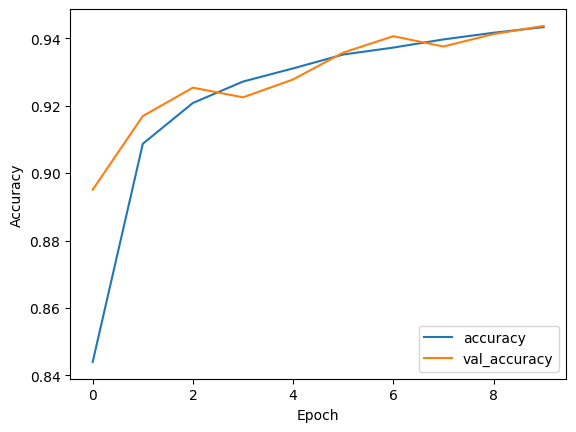

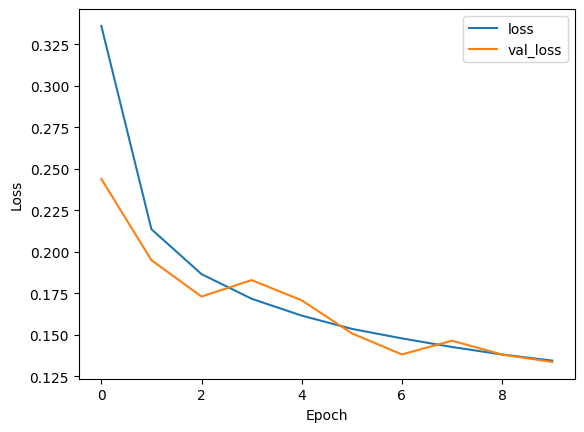

In [17]:
# Plot accuracy
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Plot loss
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

# BiLSTM

In [19]:
# Step 2: Building the BiLSTM Model

model = Sequential()
model.add(Input(shape=(X_train.shape[1], 1)))
model.add(Bidirectional(LSTM(64, return_sequences=True)))
model.add(Dropout(0.5))
model.add(Bidirectional(LSTM(32)))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [20]:
# Step 3: Training the Model

# Reshape the input to be [samples, time steps, features]
X_train_reshaped = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_reshaped = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Train the model
history = model.fit(X_train_reshaped, y_train, epochs=10, batch_size=64, validation_data=(X_test_reshaped, y_test))

# Evaluate the model
loss, accuracy = model.evaluate(X_test_reshaped, y_test)
print(f'Test Loss: {loss}, Test Accuracy: {accuracy}')

Epoch 1/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 331s 17ms/step - accuracy: 0.6852 - loss: 0.5591 - val_accuracy: 0.8762 - val_loss: 0.2651
Epoch 2/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 337s 15ms/step - accuracy: 0.8785 - loss: 0.2679 - val_accuracy: 0.9195 - val_loss: 0.1808
Epoch 3/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 321s 15ms/step - accuracy: 0.9129 - loss: 0.2011 - val_accuracy: 0.9319 - val_loss: 0.1607
Epoch 4/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 284s 15ms/step - accuracy: 0.9285 - loss: 0.1684 - val_accuracy: 0.9450 - val_loss: 0.1291
Epoch 5/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 319s 15ms/step - accuracy: 0.9379 - loss: 0.1480 - val_accuracy: 0.9499 - val_loss: 0.1191
Epoch 6/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 321s 15ms/step - accuracy: 0.9431 - loss: 0.1366 - val_accuracy: 0.9541 - val_loss: 0.1072
Epoch 7/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 322s 15ms/step - accuracy: 0.9479 - loss: 0.1254 - val_accuracy: 0.9555 - val_loss: 0.1042
Epoch 8/10
19255/19255 ━━━━━━━━━━━━━━━━━━━━ 318s 14ms/s

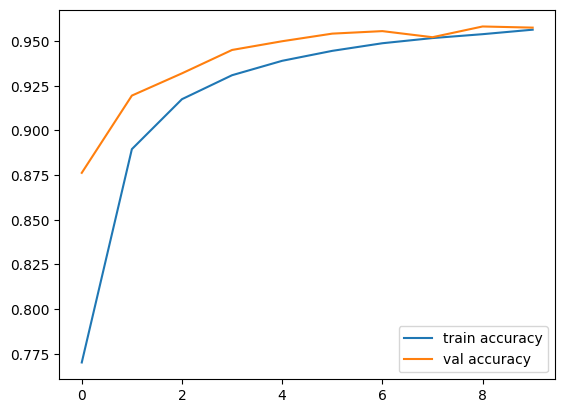

In [21]:
# Optionally, plot the training history
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.legend()
plt.show()

In [22]:
# Make predictions
y_pred_prob = model.predict(X_test_reshaped)  # Probabilities
y_pred = (y_pred_prob > 0.5).astype(int)  # Convert probabilities to binary predictions

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# Specificity (True Negative Rate)
specificity = tn / (tn + fp)

# Negative Predictive Value (NPV)
npv = tn / (tn + fn)

# False Negative Rate (FNR)
fnr = fn / (fn + tp)

# Print metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Specificity (True Negative Rate): {specificity:.4f}")
print(f"Negative Predictive Value (NPV): {npv:.4f}")
print(f"False Negative Rate (FNR): {fnr:.4f}")
print(f"AUC-ROC: {roc_auc:.4f}")

9628/9628 ━━━━━━━━━━━━━━━━━━━━ 41s 4ms/step
Accuracy: 0.9575
Precision: 0.9627
Recall: 0.9591
F1 Score: 0.9609
Specificity (True Negative Rate): 0.9556
Negative Predictive Value (NPV): 0.9514
False Negative Rate (FNR): 0.0409
AUC-ROC: 0.9943



Confusion Matrix:
[[134238   6236]
 [  6860 160741]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95    140474
           1       0.96      0.96      0.96    167601

    accuracy                           0.96    308075
   macro avg       0.96      0.96      0.96    308075
weighted avg       0.96      0.96      0.96    308075



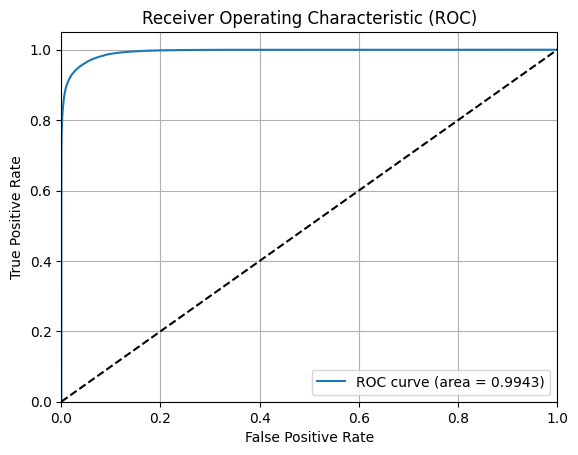

In [23]:
# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(conf_matrix)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

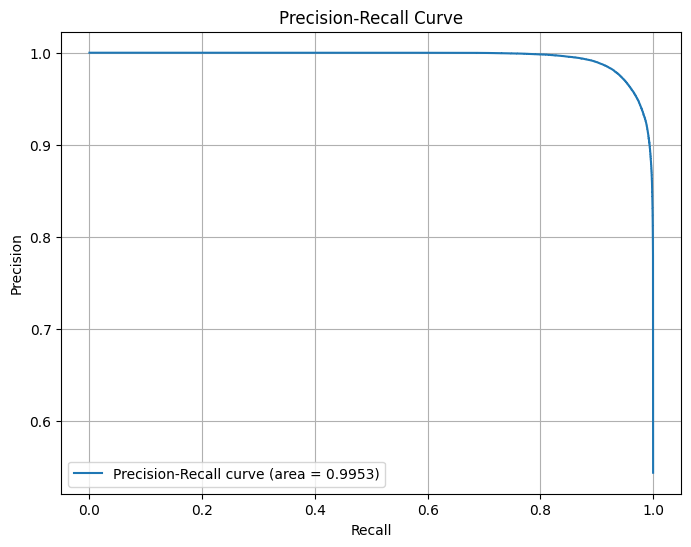

In [26]:
# 1. Plot Precision-Recall Curve

# Calculate precision and recall for different thresholds
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)

# Calculate the area under the precision-recall curve
pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall curve (area = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='best')
plt.grid(True)
plt.show()


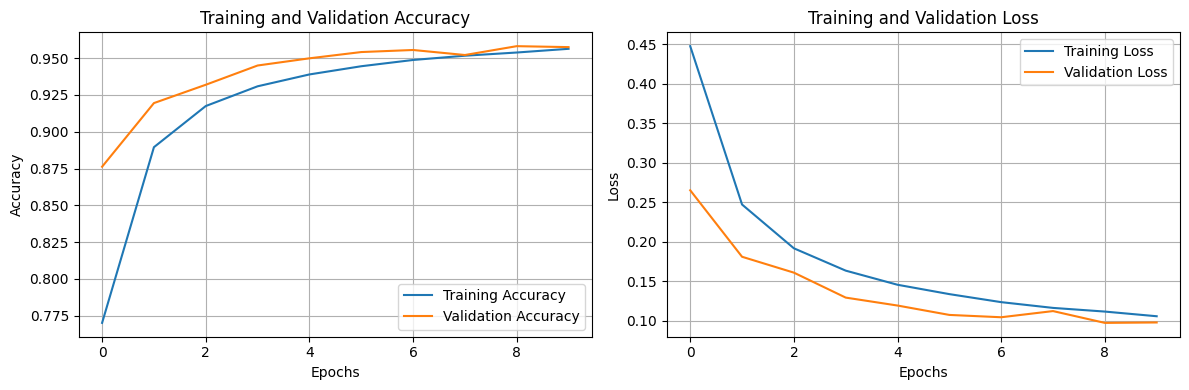

In [27]:
# 2. Plot Training and Validation Loss and Accuracy

# Assuming 'history' is the History object returned from model.fit()
history_dict = history.history

# Plot Training & Validation Accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_dict['accuracy'], label='Training Accuracy')
plt.plot(history_dict['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)

# Plot Training & Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()